Step 1, cell 1: install

In [2]:
# Install the Materials Project client and pymatgen. "-q" keeps the output quiet.
!pip install -q mp-api pymatgen

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.2 which is incompatible.


Step 1, cell 2: imports and folders

In [3]:
import os, json, warnings, datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from importlib.metadata import version

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)

# Project folders on Colab's temporary disk (wiped when the runtime resets; the optional Drive cell below saves them).
BASE = "/content/battery_project"
DATA_DIR, FIG_DIR, RES_DIR = f"{BASE}/data", f"{BASE}/figures", f"{BASE}/results"
for folder in (DATA_DIR, FIG_DIR, RES_DIR):
    os.makedirs(folder, exist_ok=True)

RAW_CSV  = f"{DATA_DIR}/raw_insertion_electrodes.csv"
META_JSON = f"{DATA_DIR}/data_pull_info.json"
RANDOM_STATE = 42          # fixes the randomness so your results are reproducible

for pkg in ("mp-api", "pymatgen", "pandas", "numpy", "scikit-learn", "matplotlib"):
    print(f"{pkg:14s} {version(pkg)}")

mp-api         0.47.0
pymatgen       2026.10.24
pandas         2.2.3
numpy          2.1.3
scikit-learn   1.6.1
matplotlib     3.10.0


Step 2: API key

In [4]:
try:
    from google.colab import userdata
    API_KEY = userdata.get("MP_API_KEY")
except Exception:
    import getpass
    API_KEY = getpass.getpass("Paste your Materials Project API key (input is hidden): ")

API_KEY = API_KEY.strip().strip('"').strip("'")      # remove accidental spaces, line breaks and quotes
print("Key length:", len(API_KEY), "(must be exactly 32)")
assert len(API_KEY) == 32, ("The key must be exactly 32 characters. Copy the full key again from the Materials Project "
                            "dashboard (the NEW site) and re-save the Colab secret.")
print("Key loaded (the key itself is never printed).")

Key length: 32 (must be exactly 32)
Key loaded (the key itself is never printed).


Step 3: connect and inspect

In [5]:
from mp_api.client import MPRester

# "with" opens the connection and closes it automatically at the end of the block.
# use_document_model=False -> results arrive as plain Python dictionaries (simple and robust).
with MPRester(API_KEY, use_document_model=False) as mpr:
    DB_VERSION = mpr.get_database_version()                            # which MP data release you are using
    AVAILABLE = mpr.materials.insertion_electrodes.available_fields    # every field this endpoint can return

print("Materials Project database version:", DB_VERSION)
print(f"{len(AVAILABLE)} fields available:")
print(AVAILABLE)

Materials Project database version: 2026.09.28
34 fields available:
['builder_meta', 'battery_type', 'material_ids', 'thermo_type', 'battery_formula', 'working_ion', 'num_steps', 'max_voltage_step', 'last_updated', 'framework', 'framework_formula', 'elements', 'nelements', 'chemsys', 'formula_anonymous', 'warnings', 'formula_charge', 'formula_discharge', 'max_delta_volume', 'average_voltage', 'capacity_grav', 'capacity_vol', 'energy_grav', 'energy_vol', 'fracA_charge', 'fracA_discharge', 'stability_charge', 'stability_discharge', 'id_charge', 'id_discharge', 'host_structure', 'adj_pairs', 'entries_composition_summary', 'electrode_object']


Step 4, cell 1: download (one working ion at a time)

In [6]:
WANTED_FIELDS = [
    "battery_type", "battery_formula", "framework_formula", "working_ion",
    "formula_charge", "formula_discharge", "id_charge", "id_discharge", "material_ids",
    "average_voltage", "capacity_grav", "capacity_vol", "energy_grav", "energy_vol",
    "max_delta_volume", "max_voltage_step", "num_steps",
    "stability_charge", "stability_discharge", "fracA_charge", "fracA_discharge",
    "elements", "nelements", "chemsys", "thermo_type", "warnings", "last_updated",
]
# 'battery_id' is deliberately NOT requested: in current mp-api it is a computed property, not a downloadable field
# (asking for it raises "invalid fields requested"). We build our own unique key in the next cell.
unknown = [f for f in WANTED_FIELDS if f not in AVAILABLE]
print("Fields this client version does not recognise (skipped):", unknown)
fields = [f for f in WANTED_FIELDS if f not in unknown]

# Ions that Materials Project has insertion electrodes for (an ion with no data is simply skipped).
WORKING_IONS = ["Li", "Na", "K", "Mg", "Ca", "Zn", "Al", "Y", "Rb", "Cs"]

docs = []
with MPRester(API_KEY, use_document_model=False) as mpr:
    route = mpr.materials.insertion_electrodes
    for ion in WORKING_IONS:
        try:
            got = route.search(working_ion=ion, fields=fields, chunk_size=1000)
        except Exception as err:
            print(f"{ion:>2}: request failed ({repr(err)[:120]}) -> skipped")
            continue
        if isinstance(got, dict) and "data" in got:    # some client versions wrap the records
            got = got["data"]
        print(f"{ion:>2}: {len(got):5d} electrodes")
        docs.extend(got)
assert len(docs) > 0, "Nothing was downloaded. Check your API key (new site!) and your internet connection."
print("Downloaded records:", len(docs))

Fields this client version does not recognise (skipped): []


Output()

✓ Retrieved 2,774 InsertionElectrodeDoc documents in 1.0s

Li:  2774 electrodes


Output()

✓ Retrieved 416 InsertionElectrodeDoc documents in 0.2s

... (21 outputs left out)

Rb:    83 electrodes


Output()

✓ Retrieved 81 InsertionElectrodeDoc documents in 0.1s

Cs:    81 electrodes
Downloaded records: 6847


Step 4, cell 2: build the table, fix the key, save

In [7]:
df_raw = pd.DataFrame(docs)

# Lists cannot be stored neatly in a CSV cell, so turn them into plain text.
for col in ("elements", "warnings"):
    if col in df_raw.columns:
        df_raw[col] = df_raw[col].apply(
            lambda v: ",".join(map(str, v)) if isinstance(v, (list, tuple)) else (v if isinstance(v, str) else ""))
for col in df_raw.columns:                     # anything still nested (dict / list) -> JSON text
    if df_raw[col].apply(lambda v: isinstance(v, (dict, list))).any():
        df_raw[col] = df_raw[col].apply(json.dumps)

if "battery_id" not in df_raw.columns:         # battery_id is not downloadable in current mp-api, so we build our own unique key
    as_text = lambda col: df_raw[col].map(lambda v: "NA" if pd.isna(v) else str(v))     # NaN-safe (pandas 3 keeps NaN when converting to text)
    key = as_text("id_charge") + "|" + as_text("id_discharge") + "|" + as_text("working_ion")
    if "thermo_type" in df_raw.columns:
        key = key + "|" + as_text("thermo_type")
    df_raw["battery_id"] = key
    print("Built our own battery_id = id_charge|id_discharge|working_ion|thermo_type")

df_raw.to_csv(RAW_CSV, index=False)

meta = {
    "pulled_utc": datetime.datetime.now(datetime.timezone.utc).isoformat(timespec="seconds"),
    "mp_database_version": DB_VERSION,
    "mp_api_version": version("mp-api"),
    "pymatgen_version": version("pymatgen"),
    "n_records": int(len(df_raw)),
    "fields_requested": fields,
}
with open(META_JSON, "w") as f:
    json.dump(meta, f, indent=2)
print("Saved:", RAW_CSV, "| rows:", len(df_raw))
print(json.dumps(meta, indent=2)[:700])

Built our own battery_id = id_charge|id_discharge|working_ion|thermo_type
Saved: /content/battery_project/data/raw_insertion_electrodes.csv | rows: 6847
{
  "pulled_utc": "2026-10-29T03:49:31+00:00",
  "mp_database_version": "2026.09.28",
  "mp_api_version": "0.47.0",
  "pymatgen_version": "2026.10.24",
  "n_records": 6847,
  "fields_requested": [
    "battery_type",
    "battery_formula",
    "framework_formula",
    "working_ion",
    "formula_charge",
    "formula_discharge",
    "id_charge",
    "id_discharge",
    "material_ids",
    "average_voltage",
    "capacity_grav",
    "capacity_vol",
    "energy_grav",
    "energy_vol",
    "max_delta_volume",
    "max_voltage_step",
    "num_steps",
    "stability_charge",
    "stability_discharge",
    "fracA_charge",
    "fracA_discharge",
    "elements",
    "nelements",
    "chemsys",
    


Step 4, cell 3: optional, copy to Google Drive

In [8]:
# OPTIONAL: copy the project folder to Google Drive so it survives a runtime reset.
from google.colab import drive
drive.mount("/content/drive")
!mkdir -p "/content/drive/MyDrive/battery_project" && cp -r /content/battery_project/* "/content/drive/MyDrive/battery_project/"
print("Copied to Google Drive > MyDrive > battery_project")

Mounted at /content/drive
Copied to Google Drive > MyDrive > battery_project


Step 5, cell 1: load and audit

In [9]:
df = pd.read_csv(RAW_CSV)
print("Rows x columns:", df.shape)

print("\nColumn types and missing values:")
print(pd.DataFrame({"dtype": df.dtypes.astype(str),
                    "missing": df.isna().sum(),
                    "missing_%": (df.isna().mean() * 100).round(1)}))

print("\nDuplicate battery_id values:", int(df["battery_id"].duplicated().sum()))
print("\nRecords per working ion:\n", df["working_ion"].value_counts())
print("\nRecords per thermo_type (the DFT recipe behind the thermodynamics):\n", df["thermo_type"].value_counts(dropna=False))

warn_text = df["warnings"].fillna("") if "warnings" in df.columns else pd.Series("", index=df.index)
n_warn = int((warn_text.str.len() > 0).sum())
print(f"\nRecords carrying a data warning: {n_warn} ({n_warn / len(df):.1%})")

num_cols = ["average_voltage", "capacity_grav", "capacity_vol", "energy_grav", "energy_vol",
            "max_delta_volume", "max_voltage_step", "stability_charge", "stability_discharge"]
print("\nSummary statistics:")
print(df[num_cols].describe(percentiles=[.01, .5, .99]).T.round(3))

Rows x columns: (6847, 28)

Column types and missing values:
                       dtype  missing  missing_%
battery_type          object        0        0.0
material_ids          object        0        0.0
thermo_type          float64     6847      100.0
battery_formula       object        0        0.0
working_ion           object        0        0.0
num_steps              int64        0        0.0
max_voltage_step     float64        0        0.0
last_updated          object        0        0.0
framework_formula     object        0        0.0
elements              object        0        0.0
nelements              int64        0        0.0
chemsys               object        0        0.0
warnings              object     5192       75.8
formula_charge        object        0        0.0
formula_discharge     object        0        0.0
max_delta_volume     float64        0        0.0
average_voltage      float64        0        0.0
capacity_grav        float64        0        0.0
capacity

Step 5, cell 2: physical sanity checks

In [10]:
# Physical sanity checks: each line counts how many rows violate a rule that should hold.
checks = {
    "voltage <= 0 V": int((df["average_voltage"] <= 0).sum()),
    "gravimetric capacity <= 0": int((df["capacity_grav"] <= 0).sum()),
    "negative energy above hull": int(((df["stability_charge"] < 0) | (df["stability_discharge"] < 0)).sum()),
    "energy_grav missing": int(df["energy_grav"].isna().sum()),
}
ratio = df["energy_grav"] / (df["average_voltage"] * df["capacity_grav"])      # should be ~1
checks["energy_grav deviates >5% from voltage x capacity"] = int(((ratio - 1).abs() > 0.05).sum())
print(pd.Series(checks, name="rows violating the rule").to_string())
print("\nMedian of energy_grav / (voltage x capacity_grav):", round(float(ratio.median()), 3), "(should be about 1)")

voltage <= 0 V                                      641
gravimetric capacity <= 0                             0
negative energy above hull                            0
energy_grav missing                                   0
energy_grav deviates >5% from voltage x capacity      0

Median of energy_grav / (voltage x capacity_grav): 1.0 (should be about 1)


Step 6: clean, with a log

In [11]:
log = []
def step(name, frame):
    """Record how many rows remain after each cleaning step."""
    log.append({"step": name, "rows_remaining": len(frame)})
    return frame

d = step("raw download", df.copy())
key_cols = ["average_voltage", "capacity_grav", "energy_grav", "stability_charge", "stability_discharge",
            "max_delta_volume", "working_ion", "framework_formula"]
d = step("drop rows missing a key field", d.dropna(subset=key_cols))
d = step("drop duplicate battery_id", d.drop_duplicates(subset="battery_id"))
V_MAX = 7.0     # ASSUMPTION: DFT "voltages" above about 7 V are treated as data errors, not battery voltages
d = step(f"keep 0 V < voltage <= {V_MAX:g} V and capacity > 0",
         d[(d["average_voltage"] > 0) & (d["average_voltage"] <= V_MAX) & (d["capacity_grav"] > 0)])

# ASSUMPTION: restrict to ONE thermodynamics recipe so voltages are comparable? None = keep all.
THERMO_FILTER = None            # None = auto: if several recipes exist, keep the most common one. Or set e.g. "GGA_GGA+U"
if THERMO_FILTER is None and d["thermo_type"].nunique() > 1:
    THERMO_FILTER = d["thermo_type"].value_counts().idxmax()
    print(f"More than one thermo_type found; keeping the most common one: {THERMO_FILTER}. Set THERMO_FILTER yourself to override.")
if THERMO_FILTER:
    d = step(f"keep thermo_type == {THERMO_FILTER}", d[d["thermo_type"] == THERMO_FILTER])

cleaning_log = pd.DataFrame(log)
cleaning_log["removed"] = (cleaning_log["rows_remaining"].shift(1) - cleaning_log["rows_remaining"]).fillna(0).astype(int)
print(cleaning_log.to_string(index=False))
if len(d) < 0.5 * len(df):
    print("\n*** WARNING: more than half of the rows were removed. Read the log above and find the step responsible before you continue. ***")
cleaning_log.to_csv(f"{RES_DIR}/cleaning_log.csv", index=False)

                                      step  rows_remaining  removed
                              raw download            6847        0
             drop rows missing a key field            6847        0
                 drop duplicate battery_id            6847        0
keep 0 V < voltage <= 7 V and capacity > 0            6187      660


Step 7, cell 1: your sustainability assumptions

In [12]:
# ASSUMPTION: which framework elements count as "supply-critical"? This is a modelling choice, not a fact of nature.
# Source to read, cite and re-check: EU Critical Raw Materials Act, Regulation (EU) 2024/1252, Annex II.
# Li itself is the working ion (not part of the framework), so it is never flagged here.
TIER_A = {"Co", "Ni"}                       # the two metals behind most cathode cost / supply-chain debates
RARE_EARTH = {"Y", "La", "Ce", "Pr", "Nd", "Sm", "Eu", "Gd", "Tb", "Dy", "Ho", "Er", "Tm", "Yb", "Lu"}
PLATINUM_GROUP = {"Ru", "Rh", "Pd", "Os", "Ir", "Pt"}
TIER_B = {"V", "Nb", "Ta", "W", "Ga", "Ge", "Sb", "Bi", "Be", "Sc", "Hf", "Sr", "As"} | RARE_EARTH | PLATINUM_GROUP
# Deliberately NOT flagged although on the EU list: Mn, Mg, Al, Ti, Si, P, B, Cu, F (abundant in bulk form).
# If you flag them too, almost everything fails, so test that choice in the sensitivity table (Step 9).
# ASSUMPTION: elements that are never acceptable in a candidate battery material, whatever its numbers look like
# (radioactive or acutely toxic). They are removed in the funnel as a separate, visible step.
RADIOACTIVE = {"Tc", "Pm", "Po", "At", "Rn", "Fr", "Ra", "Ac", "Th", "Pa", "U", "Np", "Pu", "Am", "Cm", "Bk", "Cf", "Es", "Fm", "Md", "No", "Lr"}
TOXIC = {"Cd", "Hg", "Pb", "Tl", "As", "Be"}
EXCLUDED = RADIOACTIVE | TOXIC
print("Tier A:", sorted(TIER_A))
print("Tier B:", sorted(TIER_B))
print("Never acceptable (radioactive / toxic):", sorted(EXCLUDED))

Tier A: ['Co', 'Ni']
Tier B: ['As', 'Be', 'Bi', 'Ce', 'Dy', 'Er', 'Eu', 'Ga', 'Gd', 'Ge', 'Hf', 'Ho', 'Ir', 'La', 'Lu', 'Nb', 'Nd', 'Os', 'Pd', 'Pr', 'Pt', 'Rh', 'Ru', 'Sb', 'Sc', 'Sm', 'Sr', 'Ta', 'Tb', 'Tm', 'V', 'W', 'Y', 'Yb']
Never acceptable (radioactive / toxic): ['Ac', 'Am', 'As', 'At', 'Be', 'Bk', 'Cd', 'Cf', 'Cm', 'Es', 'Fm', 'Fr', 'Hg', 'Lr', 'Md', 'No', 'Np', 'Pa', 'Pb', 'Pm', 'Po', 'Pu', 'Ra', 'Rn', 'Tc', 'Th', 'Tl', 'U']


Step 7, cell 2: engineer the features

In [13]:
d = d.copy()

# 1) Volume change in percent. The API text says "%", but its formula (max/min - 1) gives a FRACTION (0.07 = 7 %).
#    We look at the data instead of trusting either statement.
q99 = d["max_delta_volume"].quantile(0.99)
VOL_SCALE = 100.0 if q99 < 5 else 1.0        # if 99 % of the values are below 5, they must be fractions
d["volume_change_pct"] = d["max_delta_volume"] * VOL_SCALE
print(f"99th percentile of raw max_delta_volume = {q99:.3f} -> multiplied by {VOL_SCALE:g}. "
      f"Median volume change = {d['volume_change_pct'].median():.1f} %  (CHECK this against a known case in Step 8)")

# 2) Worst-case stability of the two end states (eV/atom above the convex hull)
d["e_hull_max"] = d[["stability_charge", "stability_discharge"]].max(axis=1)

# 3) Element list per record (host framework only; the working ion is NOT included) and supply-risk flags
def _element_list(row):
    for col, sep in (("elements", ","), ("chemsys", "-")):          # use 'elements'; fall back to 'chemsys' (e.g. Fe-O-P)
        v = row.get(col)
        if isinstance(v, str) and v.strip():
            return [e.strip() for e in v.split(sep) if e.strip()]
    return []
d["element_list"] = d.apply(_element_list, axis=1)
d["has_Co"] = d["element_list"].apply(lambda es: "Co" in es)
d["has_Ni"] = d["element_list"].apply(lambda es: "Ni" in es)
d["tierA_free"]  = ~d["element_list"].apply(lambda es: any(e in TIER_A for e in es))
d["tierAB_free"] = ~d["element_list"].apply(lambda es: any(e in (TIER_A | TIER_B) for e in es))
d["has_excluded"] = d["element_list"].apply(lambda es: any(e in EXCLUDED for e in es))
d["has_O"] = d["element_list"].apply(lambda es: "O" in es)                      # oxide or polyanion framework (phosphate, sulfate, silicate ...)
d["has_warning"] = d["warnings"].fillna("").astype(str).str.len() > 0           # the Materials Project attached a data warning

print("\nShare of records WITHOUT Co/Ni, by working ion (%):")
print((d.groupby("working_ion")["tierA_free"].mean() * 100).round(1).to_string())

99th percentile of raw max_delta_volume = 3.795 -> multiplied by 100. Median volume change = 5.0 %  (CHECK this against a known case in Step 8)

Share of records WITHOUT Co/Ni, by working ion (%):
working_ion
Al    80.5
Ca    83.8
Cs    93.4
K     86.4
Li    78.1
Mg    83.8
Na    85.1
Rb    89.3
Y     82.8
Zn    78.3


Step 8: validate against famous electrodes

In [14]:
# Approximate literature values for famous Li cathodes (theoretical capacity, typical average voltage).
# Used ONLY as a sanity check. Look up and cite your own sources before putting numbers in a README.
REFERENCE = [
    # (name, framework formulas that could match, reference voltage in V, reference theoretical capacity in mAh/g)
    ("LiFePO4 (olivine)", ["FePO4"], 3.4, 170),
    ("LiCoO2 (layered)",  ["CoO2"],  3.9, 274),
    ("LiMn2O4 (spinel)",  ["MnO2"],  4.1, 148),     # pymatgen reduces Mn2O4 to MnO2
]
show = ["battery_id", "framework_formula", "average_voltage", "capacity_grav", "energy_grav",
        "volume_change_pct", "e_hull_max", "num_steps", "thermo_type"]

for name, formulas, v_ref, c_ref in REFERENCE:
    sub = d[(d["working_ion"] == "Li") & (d["framework_formula"].isin(formulas))]
    print(f"\n=== {name}: literature ~{v_ref} V and ~{c_ref} mAh/g | {len(sub)} MP entries found ===")
    if len(sub):
        sub = sub.assign(dV_vs_ref=(sub["average_voltage"] - v_ref).round(2))
        sub = sub.sort_values("dV_vs_ref", key=abs)
        print(sub[show + ["dV_vs_ref"]].head(5).round(3).to_string(index=False))


=== LiFePO4 (olivine): literature ~3.4 V and ~170 mAh/g | 18 MP entries found ===
                   battery_id framework_formula  average_voltage  capacity_grav  energy_grav  volume_change_pct  e_hull_max  num_steps  thermo_type  dV_vs_ref
mp-aaaabllf|mp-aaaabcax|Li|NA             FePO4            3.405        169.891      578.457              8.894       0.027          1          NaN       0.00
mp-aaaabnqm|mp-aaabrbwl|Li|NA             FePO4            3.401        169.891      577.789             11.378       0.026          1          NaN       0.00
mp-aaabobtk|mp-aaabhhzk|Li|NA             FePO4            3.446        169.891      585.489              1.551       0.028          1          NaN       0.05
mp-aaabcrzg|mp-aaabrbtu|Li|NA             FePO4            3.338        169.891      567.151              6.123       0.008          1          NaN      -0.06
mp-aaabrpvg|mp-aaabrony|Li|NA             FePO4            3.336        169.891      566.711              9.330       0.01

Step 9, cell 1: the screening funnel

In [15]:
# ASSUMPTION: targets for a CATHODE (positive electrode). Each number is a design choice you must justify.
CRITERIA = {
    "Li": dict(v_min=3.0, v_max=4.5, cap_min=150),   # Li-ion cathodes: roughly 3-4.5 V vs Li/Li+ (above ~4.5 V common electrolytes oxidise)
    "Na": dict(v_min=2.5, v_max=4.2, cap_min=100),   # Na-ion cathodes: lower voltage and capacity are typical
}
E_HULL_MAX = 0.05      # eV/atom: both end states within 50 meV/atom of the convex hull (a common heuristic, not a law)
VOL_MAX_PCT = 10.0     # maximum volume change on cycling (%); big swings crack particles and fade capacity
REQUIRE_OXYGEN = True  # ASSUMPTION: practical cathodes are oxides or polyanion compounds (phosphates, sulfates, silicates ...). Set False to see what changes.
EXCLUDE_WARNINGS = True  # NEW: entries that carry a Materials Project warning are not trusted. Set False to see what changes.

def run_funnel(frame, ion, crit, e_hull_max, vol_max, free_col="tierA_free", require_o=None):
    """Apply the screening filters one at a time; return the survivors and the count after each step."""
    s = frame[frame["working_ion"] == ion]
    steps = [("all entries", len(s))]
    s = s[s["average_voltage"].between(crit["v_min"], crit["v_max"])]; steps.append(("voltage window", len(s)))
    s = s[s["capacity_grav"] >= crit["cap_min"]];                      steps.append(("capacity floor", len(s)))
    s = s[s["e_hull_max"] <= e_hull_max];                              steps.append(("stability (E_hull)", len(s)))
    s = s[s["volume_change_pct"] <= vol_max];                          steps.append(("volume change", len(s)))
    s = s[~s["has_excluded"]];                                         steps.append(("no radioactive/toxic element", len(s)))
    if REQUIRE_OXYGEN if require_o is None else require_o:
        s = s[s["has_O"]]
        steps.append(("contains oxygen (oxide / polyanion)", len(s)))
    if EXCLUDE_WARNINGS:                                               # NEW: drop every entry that has a Materials Project warning
        s = s[~s["has_warning"]]
        steps.append(("no Materials Project warning", len(s)))
    if free_col:
        s = s[s[free_col]]
        steps.append(("Co/Ni-free" if free_col == "tierA_free" else free_col, len(s)))
    return s.copy(), pd.DataFrame(steps, columns=["step", "n"])

SHORT, SHORT_ANY, FUNNEL = {}, {}, {}
for ion, crit in CRITERIA.items():
    SHORT_ANY[ion], _ = run_funnel(d, ion, crit, E_HULL_MAX, VOL_MAX_PCT, free_col=None)            # without sustainability filter
    SHORT[ion], FUNNEL[ion] = run_funnel(d, ion, crit, E_HULL_MAX, VOL_MAX_PCT, free_col="tierA_free")
    print(f"\n{ion}-ion cathode funnel")
    print(FUNNEL[ion].to_string(index=False))
    kept = len(SHORT[ion]) / max(len(SHORT_ANY[ion]), 1)
    print(f"-> {len(SHORT[ion])} of {len(SHORT_ANY[ion])} technically acceptable candidates ({kept:.0%}) remain after excluding Co/Ni")

pd.concat({ion: f.set_index("step")["n"] for ion, f in FUNNEL.items()}, axis=1).to_csv(f"{RES_DIR}/funnel_counts.csv")


Li-ion cathode funnel
                               step    n
                        all entries 2688
                     voltage window 1421
                     capacity floor  584
                 stability (E_hull)  161
                      volume change  121
       no radioactive/toxic element  121
contains oxygen (oxide / polyanion)  109
       no Materials Project warning   83
                         Co/Ni-free   45
-> 45 of 83 technically acceptable candidates (54%) remain after excluding Co/Ni

Na-ion cathode funnel
                               step   n
                        all entries 402
                     voltage window 213
                     capacity floor 105
                 stability (E_hull)  50
                      volume change  30
       no radioactive/toxic element  26
contains oxygen (oxide / polyanion)  26
       no Materials Project warning  17
                         Co/Ni-free  13
-> 13 of 17 technically acceptable candidates (76%) remain afte

Step 9, cell 2: sensitivity analysis

In [16]:
# Sensitivity analysis: do the conclusions survive different (equally defensible) assumptions?
rows = []
for eh in (0.025, 0.05, 0.10):
    for free_col in (None, "tierA_free", "tierAB_free"):
        for ion in CRITERIA:
            s, _ = run_funnel(d, ion, CRITERIA[ion], eh, VOL_MAX_PCT, free_col)
            rows.append({"ion": ion, "E_hull <= (eV/atom)": eh, "supply filter": free_col or "none", "survivors": len(s)})
sens = pd.DataFrame(rows).pivot_table(index=["ion", "supply filter"], columns="E_hull <= (eV/atom)", values="survivors")
print(sens.to_string())
sens.to_csv(f"{RES_DIR}/sensitivity.csv")

E_hull <= (eV/atom)  0.025  0.050  0.100
ion supply filter                       
Li  none              28.0   83.0  186.0
    tierAB_free       16.0   29.0   70.0
    tierA_free        19.0   45.0  110.0
Na  none              10.0   17.0   19.0
    tierAB_free        5.0    7.0    7.0
    tierA_free         8.0   13.0   15.0


Step 10: Pareto front

In [17]:
def pareto_mask(frame, maximize, minimize):
    """True for rows that no other row beats on ALL objectives (the Pareto front, or non-dominated set)."""
    X = np.column_stack([frame[c].to_numpy(float) for c in maximize] +
                        [-frame[c].to_numpy(float) for c in minimize])      # flip signs so that bigger is better everywhere
    mask = np.ones(len(X), dtype=bool)
    for i in range(len(X)):
        as_good = np.all(X >= X[i], axis=1)       # rows at least as good as row i on every objective
        better = np.any(X > X[i], axis=1)         # ... and strictly better on at least one
        if np.any(as_good & better):              # so row i is dominated -> not on the front
            mask[i] = False
    return mask

OBJ_MAX, OBJ_MIN = ["energy_grav"], ["e_hull_max", "volume_change_pct"]
cols = ["battery_id", "battery_formula", "framework_formula", "working_ion", "average_voltage", "capacity_grav",
        "energy_grav", "capacity_vol", "energy_vol", "e_hull_max", "volume_change_pct", "max_voltage_step",
        "num_steps", "thermo_type", "pareto"]

for ion, s in SHORT.items():
    s["pareto"] = pareto_mask(s, OBJ_MAX, OBJ_MIN) if len(s) else False
    s.sort_values("energy_grav", ascending=False, inplace=True)
    out = s[[c for c in cols if c in s.columns]]
    out.to_csv(f"{RES_DIR}/shortlist_{ion}.csv", index=False)
    print(f"\nTop {ion}-ion candidates (Co/Ni-free, passing every filter). pareto=True means not beaten on energy, stability AND volume change:")
    print(out.head(12).round(3).to_string(index=False))


Top Li-ion candidates (Co/Ni-free, passing every filter). pareto=True means not beaten on energy, stability AND volume change:
                   battery_id  battery_formula framework_formula working_ion  average_voltage  capacity_grav  energy_grav  capacity_vol  energy_vol  e_hull_max  volume_change_pct  max_voltage_step  num_steps  thermo_type  pareto
mp-aaabrfwf|mp-aaabrnhw|Li|NA        Li0-1VOF3              VOF3          Li            4.461        204.784      913.638       659.016    2940.187       0.048              3.526             0.000          1          NaN    True
mp-aaabqvyc|mp-aaabqvje|Li|NA        Li0-1VO2F              VO2F          Li            3.682        246.157      906.410       740.075    2725.139       0.049              0.277             0.000          1          NaN    True
mp-aaacujli|mp-aaafmqhp|Li|NA        Li0-1MnO2              MnO2          Li            3.150        285.493      899.400      1125.502    3545.711       0.029              0.981       

In [18]:
# A stricter 'sustainable' list: also exclude the Tier B elements (V, Nb, Ta, W, Ga, Ge, Sb, Bi, Be, Sc, Hf, Sr, As, rare earths, platinum group).
for ion in CRITERIA:
    strict = SHORT_ANY[ion][SHORT_ANY[ion]["tierAB_free"]].copy()
    strict["pareto"] = pareto_mask(strict, OBJ_MAX, OBJ_MIN) if len(strict) else False
    strict = strict.sort_values("energy_grav", ascending=False)
    strict.to_csv(f"{RES_DIR}/shortlist_{ion}_tierAB_free.csv", index=False)
    print(f"\n{ion}-ion: {len(SHORT_ANY[ion])} pass the technical filters | {len(SHORT[ion])} are Co/Ni-free | "
          f"{len(strict)} are free of Co, Ni AND Tier B elements | {int(strict['pareto'].sum())} of those are Pareto-optimal")
    print(strict[["battery_formula", "average_voltage", "capacity_grav", "energy_grav", "e_hull_max", "volume_change_pct", "pareto"]]
          .head(10).round(3).to_string(index=False))

# READ the Materials Project warnings of every top candidate. Do not trust a number you have not looked at.
for ion in CRITERIA:
    print(f"\nWarnings attached to the top {ion}-ion candidates (Co/Ni-free list):")
    print(SHORT[ion].head(12)[["battery_formula", "has_warning", "warnings"]].to_string(index=False))


Li-ion: 83 pass the technical filters | 45 are Co/Ni-free | 29 are free of Co, Ni AND Tier B elements | 13 of those are Pareto-optimal
    battery_formula  average_voltage  capacity_grav  energy_grav  e_hull_max  volume_change_pct  pareto
          Li0-1MnO2            3.150        285.493      899.400       0.029              0.981    True
   Li0-4MnCu3(PO4)4            4.129        164.118      677.610       0.043              4.654   False
         Li0-1CuPO4            4.134        161.983      669.679       0.039              0.964    True
    Li0.17-0.89MnO2            3.204        207.897      666.161       0.035              5.116   False
         Li0-1MnPO4            3.798        170.873      648.908       0.003              6.567    True
Li0-12Mn11Fe(PO4)12            3.771        170.791      644.118       0.006              6.578   False
    Li0-2MnCu(PO4)2            3.865        166.309      642.765       0.033              4.297   False
   Li0-4FeCu3(PO4)4            3

Step 11, Figure 1: voltage vs capacity

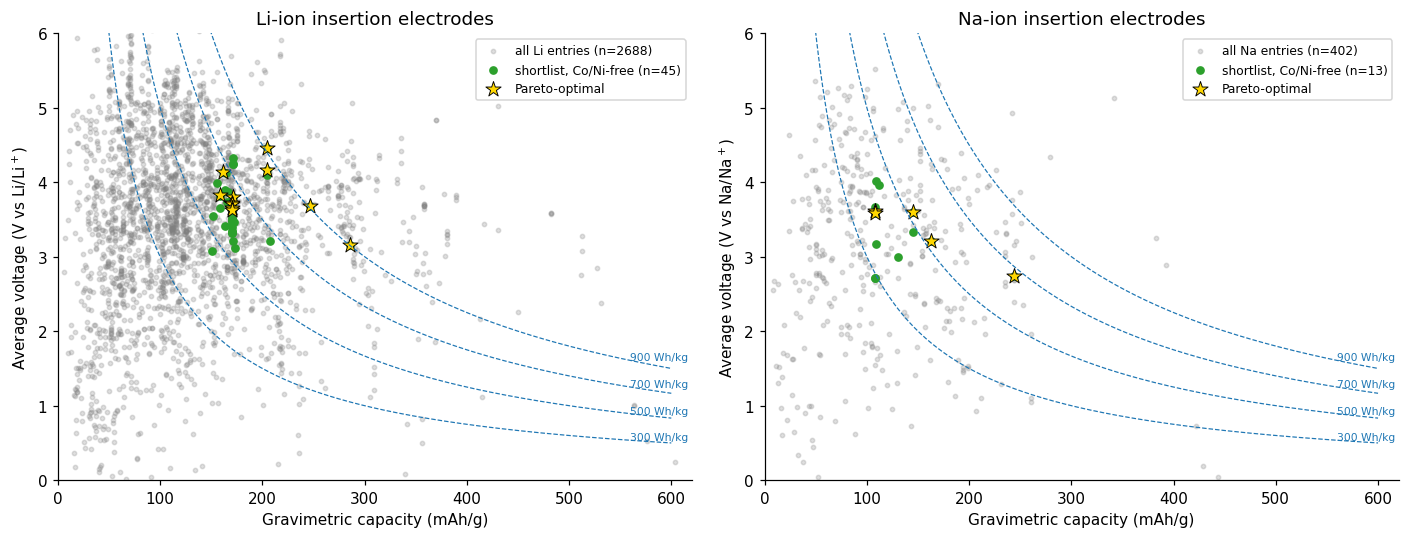

In [19]:
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

# Figure 1: voltage vs capacity, with iso-energy lines (V = E / Q)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, ion in zip(axes, CRITERIA):
    sub, sl = d[d["working_ion"] == ion], SHORT[ion]
    ax.scatter(sub["capacity_grav"], sub["average_voltage"], s=8, alpha=.25, color="grey", label=f"all {ion} entries (n={len(sub)})")
    ax.scatter(sl["capacity_grav"], sl["average_voltage"], s=22, color="tab:green", label=f"shortlist, Co/Ni-free (n={len(sl)})")
    pf = sl[sl["pareto"]]
    ax.scatter(pf["capacity_grav"], pf["average_voltage"], s=110, marker="*", color="gold", edgecolor="k", linewidth=.6, label="Pareto-optimal")
    x = np.linspace(20, 600, 300)
    for e in (300, 500, 700, 900):
        ax.plot(x, e / x, ls="--", lw=.8, color="tab:blue")
        ax.text(560, e / 560, f"{e} Wh/kg", fontsize=7, color="tab:blue")
    ax.set_xlim(0, 620); ax.set_ylim(0, 6)
    ax.set_xlabel("Gravimetric capacity (mAh/g)"); ax.set_ylabel(f"Average voltage (V vs {ion}/{ion}$^+$)")
    ax.set_title(f"{ion}-ion insertion electrodes"); ax.legend(fontsize=8, loc="upper right")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/fig1_voltage_capacity_map.png", dpi=200, bbox_inches="tight")
plt.show()

Step 11, Figures 2 and 3: funnel; energy vs stability

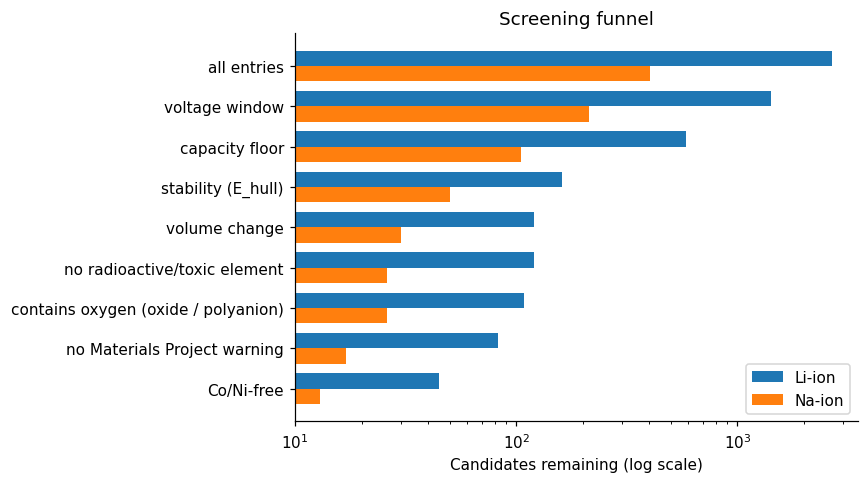

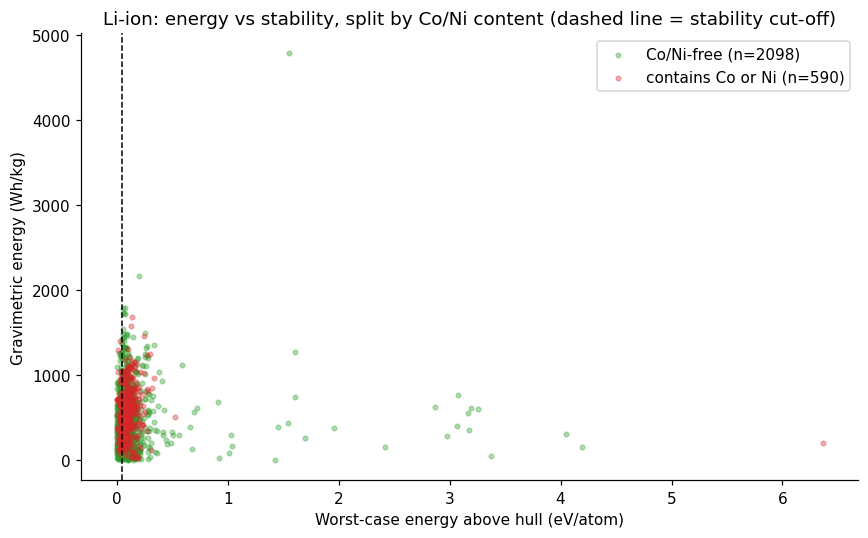

In [20]:
# Figure 2: the funnel (log scale because counts fall by orders of magnitude)
fig, ax = plt.subplots(figsize=(8, 4.5))
labels = FUNNEL["Li"]["step"].tolist()
ypos = np.arange(len(labels)); h = 0.38
for k, ion in enumerate(CRITERIA):
    ax.barh(ypos + (k - .5) * h, FUNNEL[ion]["n"].clip(lower=0.8), height=h, label=f"{ion}-ion")
ax.set_yticks(ypos); ax.set_yticklabels(labels); ax.invert_yaxis(); ax.set_xscale("log")
ax.set_xlabel("Candidates remaining (log scale)"); ax.set_title("Screening funnel"); ax.legend()
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/fig2_screening_funnel.png", dpi=200, bbox_inches="tight")
plt.show()

# Figure 3: what does the Co/Ni constraint look like in energy vs stability space? (Li-ion)
fig, ax = plt.subplots(figsize=(8, 5))
sub = d[d["working_ion"] == "Li"]
for free, colour, label in ((True, "tab:green", "Co/Ni-free"), (False, "tab:red", "contains Co or Ni")):
    z = sub[sub["tierA_free"] == free]
    ax.scatter(z["e_hull_max"], z["energy_grav"], s=9, alpha=.35, color=colour, label=f"{label} (n={len(z)})")
ax.axvline(E_HULL_MAX, color="k", ls="--", lw=1)
ax.set_xlabel("Worst-case energy above hull (eV/atom)"); ax.set_ylabel("Gravimetric energy (Wh/kg)")
ax.set_title("Li-ion: energy vs stability, split by Co/Ni content (dashed line = stability cut-off)"); ax.legend()
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/fig3_energy_vs_stability.png", dpi=200, bbox_inches="tight")
plt.show()

Step 11, Figure 4: elements and pass rates

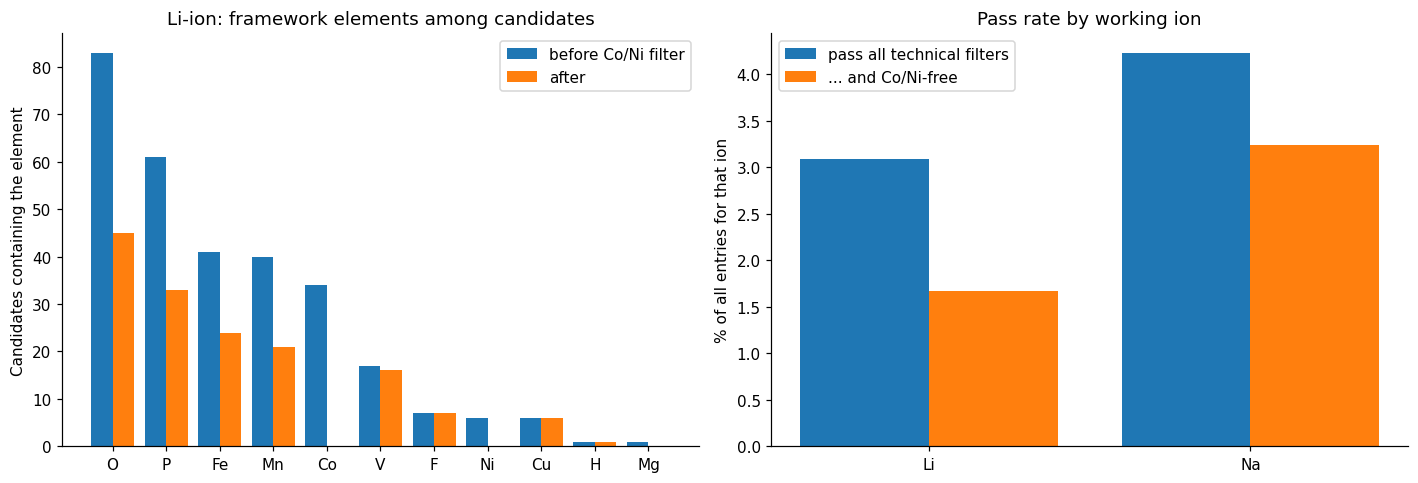

In [21]:
# Figure 4: which elements dominate the Li-ion candidates, and how do the ions compare by pass RATE?
from collections import Counter
def element_counts(frame):
    return Counter(e for es in frame["element_list"] for e in es if e)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
before, after = element_counts(SHORT_ANY["Li"]), element_counts(SHORT["Li"])
top = [e for e, _ in before.most_common(12)]
x = np.arange(len(top)); w = .4
axes[0].bar(x - w / 2, [before[e] for e in top], w, label="before Co/Ni filter")
axes[0].bar(x + w / 2, [after[e] for e in top], w, label="after")
axes[0].set_xticks(x); axes[0].set_xticklabels(top)
axes[0].set_ylabel("Candidates containing the element"); axes[0].set_title("Li-ion: framework elements among candidates"); axes[0].legend()

rates = {}
for ion in CRITERIA:
    n_all = max(int((d["working_ion"] == ion).sum()), 1)
    rates[ion] = (len(SHORT_ANY[ion]) / n_all * 100, len(SHORT[ion]) / n_all * 100)
pos = np.arange(len(rates))
axes[1].bar(pos - w / 2, [r[0] for r in rates.values()], w, label="pass all technical filters")
axes[1].bar(pos + w / 2, [r[1] for r in rates.values()], w, label="... and Co/Ni-free")
axes[1].set_xticks(pos); axes[1].set_xticklabels(list(rates))
axes[1].set_ylabel("% of all entries for that ion"); axes[1].set_title("Pass rate by working ion"); axes[1].legend()
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/fig4_elements_and_pass_rates.png", dpi=200, bbox_inches="tight")
plt.show()

Li vs Na, same host (Figure 5)

Host formulas present for BOTH Li and Na: 197
Median dV (Na - Li) = -0.15 V | mean = -0.11 V | share of hosts where Na is lower: 64%


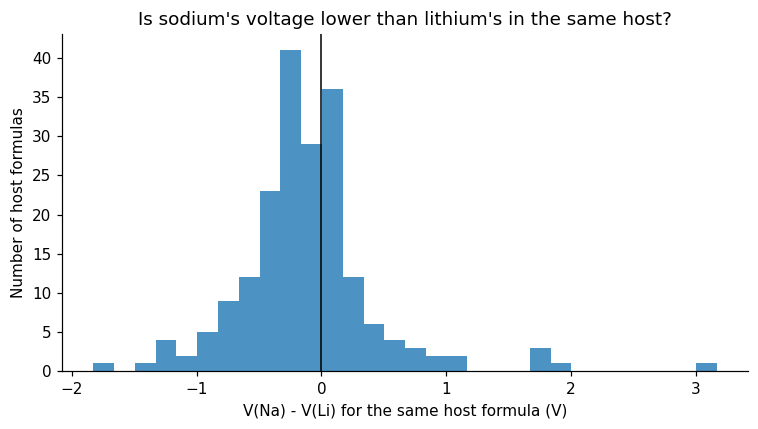

CAUTION: the same formula does NOT guarantee the same crystal structure. Say so in your README.


In [22]:
# Pair Li and Na entries that share the same host formula (keep the most stable entry per formula and ion).
best = d.sort_values("e_hull_max").drop_duplicates(subset=["framework_formula", "working_ion"], keep="first")
li = best[best["working_ion"] == "Li"][["framework_formula", "average_voltage"]].rename(columns={"average_voltage": "V_Li"})
na = best[best["working_ion"] == "Na"][["framework_formula", "average_voltage"]].rename(columns={"average_voltage": "V_Na"})
pairs = li.merge(na, on="framework_formula")
pairs["dV_Na_minus_Li"] = pairs["V_Na"] - pairs["V_Li"]
print(f"Host formulas present for BOTH Li and Na: {len(pairs)}")
if len(pairs):
    print(f"Median dV (Na - Li) = {pairs['dV_Na_minus_Li'].median():+.2f} V | mean = {pairs['dV_Na_minus_Li'].mean():+.2f} V | "
          f"share of hosts where Na is lower: {(pairs['dV_Na_minus_Li'] < 0).mean():.0%}")
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.hist(pairs["dV_Na_minus_Li"], bins=30, color="tab:blue", alpha=.8)
    ax.axvline(0, color="k", lw=1)
    ax.set_xlabel("V(Na) - V(Li) for the same host formula (V)"); ax.set_ylabel("Number of host formulas")
    ax.set_title("Is sodium's voltage lower than lithium's in the same host?")
    plt.tight_layout()
    plt.savefig(f"{FIG_DIR}/fig5_li_vs_na_voltage_offset.png", dpi=200, bbox_inches="tight")
    plt.show()
    pairs.sort_values("dV_Na_minus_Li").to_csv(f"{RES_DIR}/li_vs_na_pairs.csv", index=False)
print("CAUTION: the same formula does NOT guarantee the same crystal structure. Say so in your README.")

Step 12, cell 1: features from the formula (with the fixes)

In [23]:
from pymatgen.core import Composition, Element

# Use ONE thermodynamics recipe (the most common) so that the labels are comparable.
if d["thermo_type"].notna().any():
    main_thermo = d["thermo_type"].mode()[0]
    ml = d[d["thermo_type"] == main_thermo].reset_index(drop=True)
else:                                          # MP did not record thermo_type for these rows: use all rows
    main_thermo = "not recorded"
    ml = d.reset_index(drop=True)
assert len(ml) >= 50, "Too few rows left for machine learning: check the cleaning log in Step 6."
if "chemsys" not in ml.columns:                # chemsys is used for the strict grouped split; fill any gaps from the element list
    ml["chemsys"] = np.nan
ml["chemsys"] = ml["chemsys"].where(ml["chemsys"].notna(), ml["element_list"].apply(lambda es: "-".join(sorted(es))))
print(f"ML uses thermo_type = {main_thermo}: {len(ml)} of {len(d)} rows, {ml['framework_formula'].nunique()} distinct host frameworks")

_cache = {}
def eprops(symbol):
    """Look up a few physical properties of one element (cached, because we ask for the same elements many times)."""
    if symbol not in _cache:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")                    # pymatgen warns for elements without an electronegativity
            el = Element(symbol)
            num = lambda v: float(v) if v is not None else np.nan
            _cache[symbol] = {"X": num(el.X), "mass": num(el.atomic_mass), "radius": num(el.atomic_radius),
                              "row": num(el.row), "group": num(el.group), "tm": float(el.is_transition_metal)}
    return _cache[symbol]

ANIONS = ["O", "S", "Se", "F", "Cl", "N", "P"]

def featurize(formula):
    """Turn a chemical formula into numbers: fraction-weighted mean / min / max / range of element properties, etc."""
    amount = Composition(formula).fractional_composition.get_el_amt_dict()      # {element: atomic fraction}
    els, frac = list(amount), np.array(list(amount.values()), dtype=float)
    f = {"n_elements": len(els)}
    for prop in ("X", "mass", "radius", "row", "group"):
        vals = np.array([eprops(e)[prop] for e in els]); ok = ~np.isnan(vals)
        if ok.any():
            wts = frac[ok] / frac[ok].sum()
            f[f"{prop}_mean"] = float((wts * vals[ok]).sum())
            f[f"{prop}_min"], f[f"{prop}_max"] = float(vals[ok].min()), float(vals[ok].max())
            f[f"{prop}_range"] = f[f"{prop}_max"] - f[f"{prop}_min"]
        else:
            f.update({f"{prop}_{k}": np.nan for k in ("mean", "min", "max", "range")})
    f["frac_transition_metal"] = float(sum(fr for e, fr in zip(els, frac) if eprops(e)["tm"] == 1.0))
    for a in ANIONS:
        f[f"frac_{a}"] = float(amount.get(a, 0.0))
    return f

features = {}
for fm in ml["framework_formula"].unique():
    try:
        features[fm] = featurize(fm)
    except Exception as err:                   # a formula pymatgen cannot read: skip it, but say so
        print("Skipping a formula pymatgen cannot read:", fm, "|", repr(err)[:80])
table = pd.DataFrame(features).T.astype(float)                                   # one row per formula
ml = ml[ml["framework_formula"].isin(table.index)].reset_index(drop=True)
X = table.loc[ml["framework_formula"]].reset_index(drop=True).join(pd.get_dummies(ml["working_ion"], prefix="ion").astype(float))
y = ml["average_voltage"].astype(float)
print("Feature matrix:", X.shape)
print(X.head(3).round(3).to_string())

ML uses thermo_type = not recorded: 6187 of 6187 rows, 2783 distinct host frameworks
Feature matrix: (6187, 39)
   n_elements  X_mean  X_min  X_max  X_range  mass_mean  mass_min  mass_max  mass_range  radius_mean  radius_min  radius_max  radius_range  row_mean  row_min  row_max  row_range  group_mean  group_min  group_max  group_range  frac_transition_metal  frac_O  frac_S  frac_Se  frac_F  frac_Cl  frac_N  frac_P  ion_Al  ion_Ca  ion_Cs  ion_K  ion_Li  ion_Mg  ion_Na  ion_Rb  ion_Y  ion_Zn
0         3.0   3.048   0.82   3.98     3.16     27.876    18.998    58.693      39.695        0.972         0.5         2.2           1.7     2.667      2.0      4.0        2.0      12.667        1.0       17.0         16.0                  0.111   0.000     0.0      0.0   0.667      0.0     0.0   0.000     0.0     0.0     0.0    0.0     1.0     0.0     0.0     0.0    0.0     0.0
1         5.0   3.094   1.63   3.98     2.35     23.909    15.999    55.845      39.846        0.754         0.5        

Step 12, cell 2: models and honest validation

In [24]:
from sklearn.model_selection import KFold, GroupKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, r2_score

from sklearn.base import BaseEstimator, RegressorMixin

class PerIonMean(BaseEstimator, RegressorMixin):
    """Baseline: predict the mean voltage of the SAME working ion in the training data (uses only the ion_* columns)."""
    def fit(self, X, y):
        self.ion_cols_ = [c for c in X.columns if c.startswith("ion_")]
        ion = np.asarray(X[self.ion_cols_]).argmax(axis=1)
        y = np.asarray(y, dtype=float)
        self.means_ = {i: y[ion == i].mean() for i in np.unique(ion)}
        self.global_mean_ = y.mean()
        return self
    def predict(self, X):
        ion = np.asarray(X[self.ion_cols_]).argmax(axis=1)
        return np.array([self.means_.get(i, self.global_mean_) for i in ion])

models = {
    "Baseline (always predict the mean)": DummyRegressor(strategy="mean"),
    "Per-ion baseline (mean of the same ion)": PerIonMean(),
    "Ridge regression": make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), Ridge(alpha=1.0)),
    "Random forest": make_pipeline(SimpleImputer(strategy="median"),
                                   RandomForestRegressor(n_estimators=200, min_samples_leaf=2, n_jobs=-1, random_state=RANDOM_STATE)),
}
splits = {   # name -> (splitter, groups). Groups keep related rows together, so they are never split between train and test.
    "random 5-fold (leaky, optimistic)":   (KFold(5, shuffle=True, random_state=RANDOM_STATE), None),
    "grouped by host framework":           (GroupKFold(5), ml["framework_formula"]),
    "grouped by chemical system (strict)": (GroupKFold(5), ml["chemsys"]),
}

rows, PRED = [], {}
for split_name, (cv, groups) in splits.items():
    for model_name, model in models.items():
        pred = cross_val_predict(model, X, y, cv=cv, groups=groups)     # every row is predicted by a model that never saw it
        PRED[(split_name, model_name)] = pred
        rows.append({"split": split_name, "model": model_name,
                     "MAE (V)": mean_absolute_error(y, pred), "R2": r2_score(y, pred)})
cv_results = pd.DataFrame(rows)
print(cv_results.round(3).to_string(index=False))
cv_results.to_csv(f"{RES_DIR}/ml_cv_results.csv", index=False)

                              split                                   model  MAE (V)     R2
  random 5-fold (leaky, optimistic)      Baseline (always predict the mean)    1.155 -0.000
  random 5-fold (leaky, optimistic) Per-ion baseline (mean of the same ion)    0.933  0.303
  random 5-fold (leaky, optimistic)                        Ridge regression    0.717  0.567
  random 5-fold (leaky, optimistic)                           Random forest    0.492  0.753
          grouped by host framework      Baseline (always predict the mean)    1.157 -0.002
          grouped by host framework Per-ion baseline (mean of the same ion)    0.935  0.299
          grouped by host framework                        Ridge regression    0.723  0.559
          grouped by host framework                           Random forest    0.561  0.699
grouped by chemical system (strict)      Baseline (always predict the mean)    1.155 -0.000
grouped by chemical system (strict) Per-ion baseline (mean of the same ion)    0

Step 12, cell 3: Figure 6

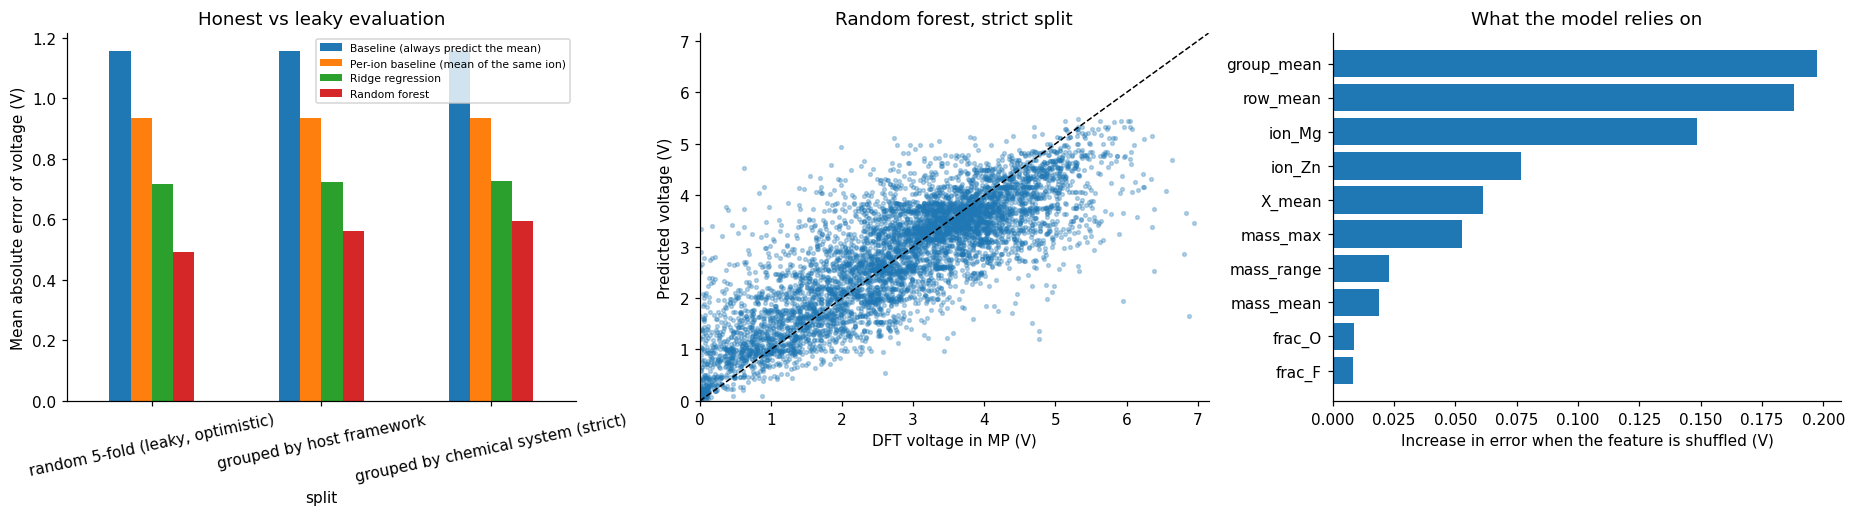

In [25]:
from sklearn.inspection import permutation_importance

strict, best = "grouped by chemical system (strict)", "Random forest"
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))

# (a) Error by split and model: the gap between "random" and "strict" is how much leakage flatters the model
piv = cv_results.pivot(index="split", columns="model", values="MAE (V)")[list(models)].loc[list(splits)]
piv.plot.bar(ax=axes[0], rot=12); axes[0].set_ylabel("Mean absolute error of voltage (V)"); axes[0].set_title("Honest vs leaky evaluation")
axes[0].legend(fontsize=7)

# (b) Predicted vs DFT voltage under the strict split
p = PRED[(strict, best)]
lim = [0, float(max(y.max(), p.max()) + .2)]
axes[1].scatter(y, p, s=6, alpha=.3); axes[1].plot(lim, lim, "k--", lw=1)
axes[1].set_xlim(lim); axes[1].set_ylim(lim)
axes[1].set_xlabel("DFT voltage in MP (V)"); axes[1].set_ylabel("Predicted voltage (V)"); axes[1].set_title(f"{best}, strict split")

# (c) What does the model rely on? Permutation importance on one held-out chemical-system fold
train_idx, test_idx = next(GroupKFold(5).split(X, y, ml["chemsys"]))
fitted = models[best].fit(X.iloc[train_idx], y.iloc[train_idx])
imp = permutation_importance(fitted, X.iloc[test_idx], y.iloc[test_idx], n_repeats=5,
                             random_state=RANDOM_STATE, scoring="neg_mean_absolute_error")
order = np.argsort(imp.importances_mean)[-10:]
axes[2].barh(X.columns[order], imp.importances_mean[order])
axes[2].set_xlabel("Increase in error when the feature is shuffled (V)"); axes[2].set_title("What the model relies on")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/fig6_ml_voltage.png", dpi=200, bbox_inches="tight")
plt.show()

Step 13, cell 1: headline numbers

In [26]:
def row_of(split_prefix, model_prefix):
    m = cv_results[cv_results["split"].str.startswith(split_prefix) & cv_results["model"].str.startswith(model_prefix)]
    return m.iloc[0]

best_strict  = row_of("grouped by chemical", "Random forest")
base_strict  = row_of("grouped by chemical", "Baseline (always")
ion_base_strict = row_of("grouped by chemical", "Per-ion")
best_leaky   = row_of("random", "Random forest")

summary = {
    "n_records_downloaded": int(len(df)),
    "n_records_after_cleaning": int(len(d)),
    "criteria": CRITERIA, "e_hull_max_eV_per_atom": E_HULL_MAX, "volume_change_max_pct": VOL_MAX_PCT,
    "funnel": {ion: {k: int(v) for k, v in FUNNEL[ion].set_index("step")["n"].items()} for ion in FUNNEL},
    "pass_all_technical_filters": {ion: int(len(SHORT_ANY[ion])) for ion in SHORT_ANY},
    "pass_and_Co_Ni_free": {ion: int(len(SHORT[ion])) for ion in SHORT},
    "pareto_optimal": {ion: int(SHORT[ion]["pareto"].sum()) for ion in SHORT},
    "ml": {"thermo_type_used": str(main_thermo),
           "MAE_baseline_strict_V": round(float(base_strict["MAE (V)"]), 3),
           "MAE_per_ion_baseline_strict_V": round(float(ion_base_strict["MAE (V)"]), 3),
           "MAE_random_forest_strict_V": round(float(best_strict["MAE (V)"]), 3),
           "MAE_random_forest_random_split_V": round(float(best_leaky["MAE (V)"]), 3)},
}
with open(f"{RES_DIR}/results_summary.json", "w") as f:
    json.dump(summary, f, indent=2, default=str)

print("HEADLINE NUMBERS (write your README findings from these, in your own words):")
for ion in CRITERIA:
    print(f"  {ion}: {len(SHORT_ANY[ion])} entries pass every technical filter; {len(SHORT[ion])} of them are Co/Ni-free; "
          f"{summary['pareto_optimal'][ion]} are Pareto-optimal")
print(f"  Voltage from composition, strict split: MAE {best_strict['MAE (V)']:.2f} V vs {ion_base_strict['MAE (V)']:.2f} V for the per-ion baseline "
      f"and {base_strict['MAE (V)']:.2f} V for the plain mean; "
      f"the leaky random split would have claimed {best_leaky['MAE (V)']:.2f} V")

HEADLINE NUMBERS (write your README findings from these, in your own words):
  Li: 83 entries pass every technical filter; 45 of them are Co/Ni-free; 11 are Pareto-optimal
  Na: 17 entries pass every technical filter; 13 of them are Co/Ni-free; 5 are Pareto-optimal
  Voltage from composition, strict split: MAE 0.59 V vs 0.93 V for the per-ion baseline and 1.16 V for the plain mean; the leaky random split would have claimed 0.49 V


Step 13, cell 2: versions and zip

In [27]:
# Record the exact package versions (this becomes requirements.txt in your GitHub repo).
with open(f"{RES_DIR}/requirements.txt", "w") as f:
    for pkg in ("mp-api", "pymatgen", "pandas", "numpy", "scikit-learn", "matplotlib"):
        f.write(f"{pkg}=={version(pkg)}\n")

# Zip data + figures + results and download the zip to your computer.
import shutil
shutil.make_archive("/content/battery_project_outputs", "zip", BASE)
try:
    from google.colab import files
    files.download("/content/battery_project_outputs.zip")
except Exception:
    print("Zip saved at /content/battery_project_outputs.zip (open the Files panel on the left to download it).")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>